First step Loading Data from the data set and splitting them into categories

In [3]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler

dataset = 'D:/NeuralNetworks/Human Face Emotions/Data'
categories = ['Angry' , 'Fear', 'Happy','Sad','Suprise']

IMG_SIZE = 48
data = []
labels = []

for category_idx, category in enumerate(categories):
    Dataset_path = os.path.join(dataset , category)
    if not os.path.exists(Dataset_path):
        continue
    for img_name in os.listdir(Dataset_path):
        img_path = os.path.join(Dataset_path,img_name)
        try:
            img = cv2.imread(img_path,cv2.IMREAD_GRAYSCALE)
            img_resized = cv2.resize(img,(IMG_SIZE,IMG_SIZE))
            img_flattened = img_resized.flatten()
            data.append(img_flattened)
            labels.append(category_idx)
        except Exception as e:
            pass
X = np.array(data)
y = np.array(labels)

print (f"Number of images is : {len(X)}")
print(f"Shape of X: {X.shape}")

Number of images is : 59099
Shape of X: (59099, 2304)


Step two Preprocessing

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler_minmax = MinMaxScaler()
X_train_norm = scaler_minmax.fit_transform(X_train)
X_test_norm = scaler_minmax.transform(X_test)

scaler_std = StandardScaler()
X_train_std = scaler_std.fit_transform(X_train)
X_test_std = scaler_std.transform(X_test)

print("Preprocessing complete.")

Preprocessing complete.


third step Additional Preprocessing

In [5]:
from sklearn.decomposition import PCA
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam, SGD

pca = PCA(n_components=100, random_state=42)
X_train_pca = pca.fit_transform(X_train_std)
X_test_pca = pca.transform(X_test_std)

print(f"Original Feature Size: {X_train.shape[1]}")
print(f"PCA Reduced Feature Size: {X_train_pca.shape[1]}")

Original Feature Size: 2304
PCA Reduced Feature Size: 100


fourth step MLP MODEL

In [6]:
num_classes = len(categories)

def build_shallow_mlp(input_dim, num_classes=num_classes, activation='relu'):
    model = Sequential([
        Dense(128, activation=activation, input_shape=(input_dim,)),
        Dense(num_classes, activation='softmax')
    ])
    return model

def build_deep_mlp(input_dim, num_classes=num_classes, activation='relu'):
    model = Sequential([
        Dense(512, activation=activation, input_shape=(input_dim,)),
        BatchNormalization(),
        Dropout(0.3),
        
        Dense(256, activation=activation),
        BatchNormalization(),
        Dropout(0.3),
        
        Dense(128, activation=activation),
        BatchNormalization(),
        Dropout(0.2),
        
        Dense(64, activation=activation),
        Dense(num_classes, activation='softmax')
    ])
    return model

def build_wide_mlp(input_dim, num_classes=num_classes, activation='relu'):
    model = Sequential([
        Dense(1024, activation=activation, input_shape=(input_dim,)),
        Dropout(0.4),
        Dense(512, activation=activation),
        Dropout(0.4),
        Dense(num_classes, activation='softmax')
    ])
    return model

5th step Experimentation

In [10]:
experiments = [
    {"name": "Exp 1: Shallow + MinMax + ReLU + Adam", "builder": build_shallow_mlp, "X_tr": X_train_norm, "X_te": X_test_norm, "act": "relu", "opt": Adam(learning_rate=0.001)},
    {"name": "Exp 2: Shallow + Standard + Tanh + SGD", "builder": build_shallow_mlp, "X_tr": X_train_std, "X_te": X_test_std, "act": "tanh", "opt": SGD(learning_rate=0.01)},
    {"name": "Exp 3: Deep + MinMax + ReLU + Adam",    "builder": build_deep_mlp,    "X_tr": X_train_norm, "X_te": X_test_norm, "act": "relu", "opt": Adam(learning_rate=0.0005)},
    {"name": "Exp 4: Deep + Standard + ReLU + Adam",  "builder": build_deep_mlp,    "X_tr": X_train_std,  "X_te": X_test_std,  "act": "relu", "opt": Adam(learning_rate=0.0005)},
    {"name": "Exp 5: Deep + PCA + ReLU + Adam",       "builder": build_deep_mlp,    "X_tr": X_train_pca,  "X_te": X_test_pca,  "act": "relu", "opt": Adam(learning_rate=0.0005)},
    {"name": "Exp 6: Wide + Standard + ReLU + Adam",  "builder": build_wide_mlp,    "X_tr": X_train_std,  "X_te": X_test_std,  "act": "relu", "opt": Adam(learning_rate=0.001)},
]

results = []
histories = {}
trained_models = {}

for exp in experiments:
    print(f"\nRunning {exp['name']}")
    model = exp["builder"](input_dim=exp["X_tr"].shape[1], activation=exp["act"])
    model.compile(optimizer=exp["opt"], loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    
    history = model.fit(
        exp["X_tr"], y_train,
        validation_data=(exp["X_te"], y_test),
        epochs=30,
        batch_size=64,
        verbose=1
    )
    
    test_loss, test_acc = model.evaluate(exp["X_te"], y_test, verbose=0)
    
    results.append({
        "Experiment Name": exp["name"],
        "Test Accuracy (%)": round(test_acc * 100, 2),
        "Test Loss": round(test_loss, 4)
    })
    
    histories[exp["name"]] = history
    trained_models[exp["name"]] = model


Running Exp 1: Shallow + MinMax + ReLU + Adam


d:\NeuralNetworks\.venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/30
739/739 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.3656 - loss: 1.5089 - val_accuracy: 0.3932 - val_loss: 1.4526
Epoch 2/30
739/739 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.4094 - loss: 1.4258 - val_accuracy: 0.3934 - val_loss: 1.4489
Epoch 3/30
739/739 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.4230 - loss: 1.3935 - val_accuracy: 0.4225 - val_loss: 1.3895
Epoch 4/30
739/739 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.4331 - loss: 1.3737 - val_accuracy: 0.4419 - val_loss: 1.3586
Epoch 5/30
739/739 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.4405 - loss: 1.3580 - val_accuracy: 0.4439 - val_loss: 1.3494
Epoch 6/30
739/739 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.4455 - loss: 1.3411 - val_accuracy: 0.4403 - val_loss: 1.3506
Epoch 7/30
739/739 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.4513 - loss: 1.3287 - val_accuracy: 0.4398 - val_loss: 1.3453
Epoch 8/30
739/739 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.4554 - loss: 1.3188 - val_accuracy: 0.

Experiment Comparison

In [11]:
df_results = pd.DataFrame(results).sort_values(by="Test Accuracy (%)", ascending=False)
print("--- Experiment Comparison Summary ---")
df_results

--- Experiment Comparison Summary ---


,Experiment Name,Test Accuracy (%),Test Loss
3,Exp 4: Deep + Standard + ReLU + Adam,72.13,0.7807
4,Exp 5: Deep + PCA + ReLU + Adam,70.99,0.7841
1,Exp 2: Shallow + Standard + Tanh + SGD,70.45,0.9007
5,Exp 6: Wide + Standard + ReLU + Adam,54.80,1.0944
0,Exp 1: Shallow + MinMax + ReLU + Adam,49.37,1.2469
2,Exp 3: Deep + MinMax + ReLU + Adam,45.77,1.3013


Loss & Accuracy Visualization Curves

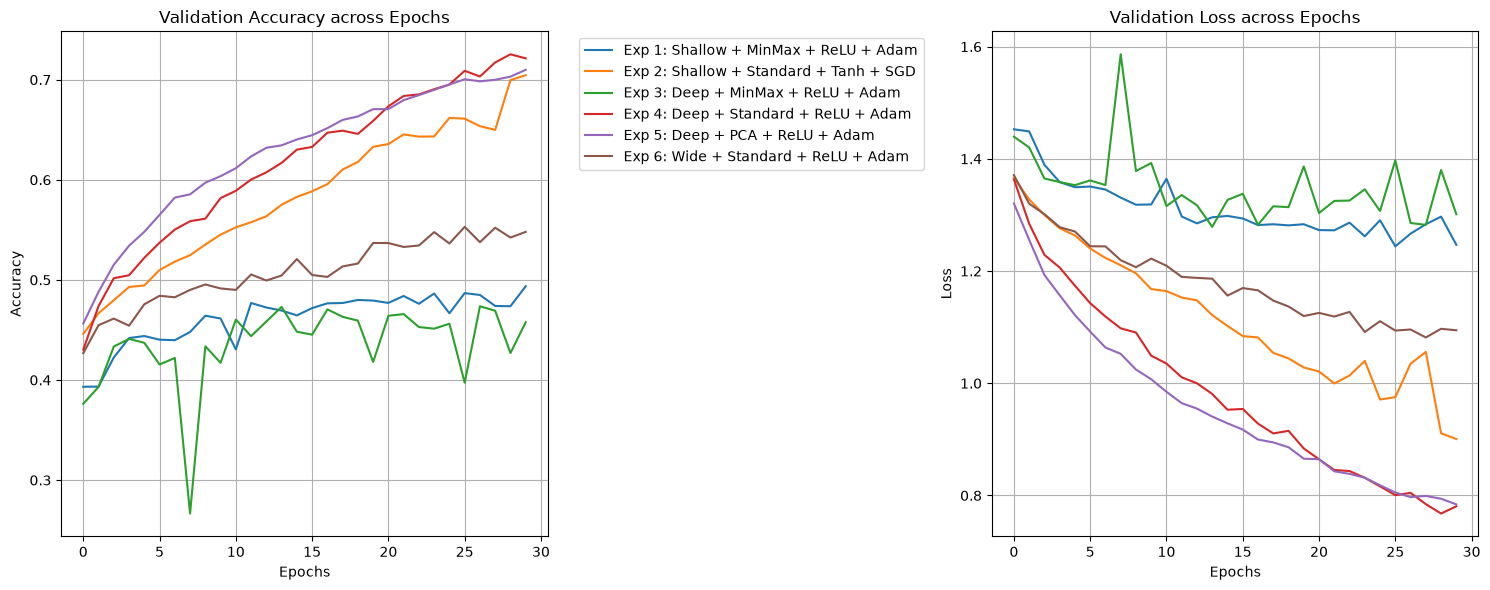

In [15]:
plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
for name, hist in histories.items():
    plt.plot(hist.history['val_accuracy'], label=name)
plt.title('Validation Accuracy across Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)

plt.subplot(1, 2, 2)
for name, hist in histories.items():
    plt.plot(hist.history['val_loss'], label=name)
plt.title('Validation Loss across Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid(True)

plt.tight_layout()
plt.show()

370/370 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
--- Classification Report for Exp 4: Deep + Standard + ReLU + Adam ---

              precision    recall  f1-score   support

       Angry       0.73      0.61      0.66      2030
        Fear       0.69      0.53      0.60      1946
       Happy       0.80      0.84      0.82      3688
         Sad       0.60      0.73      0.66      2511
     Suprise       0.79      0.81      0.80      1645

    accuracy                           0.72     11820
   macro avg       0.72      0.70      0.71     11820
weighted avg       0.72      0.72      0.72     11820



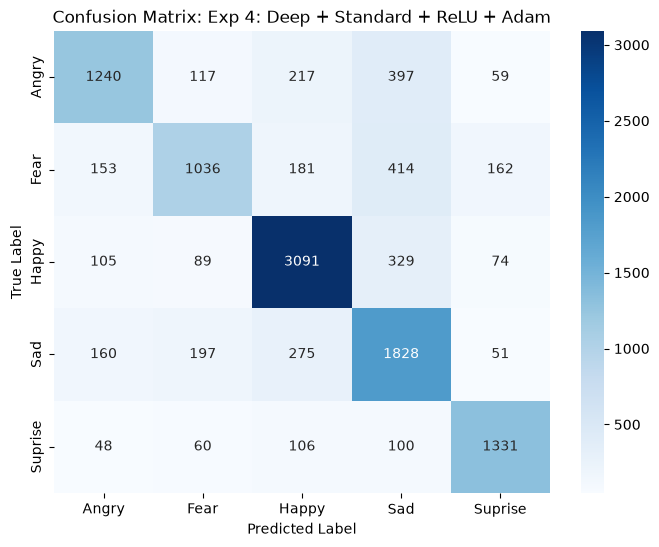

In [16]:
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

best_exp_name = df_results.iloc[0]["Experiment Name"]
best_exp_config = next(exp for exp in experiments if exp["name"] == best_exp_name)
best_model = trained_models[best_exp_name]

y_pred_probs = best_model.predict(best_exp_config["X_te"])
y_pred = np.argmax(y_pred_probs, axis=1)

print(f"--- Classification Report for {best_exp_name} ---\n")
print(classification_report(y_test, y_pred, target_names=categories))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=categories, yticklabels=categories)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title(f'Confusion Matrix: {best_exp_name}')
plt.show()